## Ćwiczenie 11: Formalizm przekształceń geometrycznych (implementacja od zera)

Zanim przejdziemy do gotowych bibliotek, zbudujemy system przekształceń geometrycznych całkowicie od zera, wykorzystując **macierze przejścia** i **współrzędne jednorodne** $(x, y, 1)$.

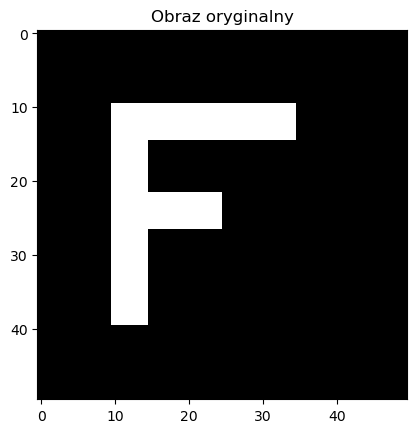

In [27]:
import numpy as np
import matplotlib.pyplot as plt

# Tworzymy prosty, asymetryczny obraz testowy (litera 'F'), 
# dzięki któremu łatwo zauważymy obroty i odbicia.
img = np.zeros((50, 50))
img[10:40, 10:15] = 1  # Pionowa kreska
img[10:15, 10:35] = 1  # Górna pozioma
img[22:27, 10:25] = 1  # Środkowa pozioma

plt.imshow(img, cmap='gray')
plt.title("Obraz oryginalny")
plt.show()

### 1. Macierze Transformacji w 2D
Wykorzystujemy wymiar 3x3, aby móc reprezentować przesunięcie (translację) za pomocą mnożenia macierzy. Jest to standard tzw. współrzędnych jednorodnych.

In [18]:
def get_translation_matrix(tx, ty):
    """Przesunięcie w poziomie (tx) i pionie (ty)"""
    return np.array([
        [1, 0, tx],
        [0, 1, ty],
        [0, 0, 1]
    ])

def get_scaling_matrix(sx, sy):
    """Skalowanie poziome (sx) i pionowe (sy)"""
    return np.array([
        [sx, 0,  0],
        [0,  sy, 0],
        [0,  0,  1]
    ])

def get_rotation_matrix(angle_deg):
    """Obrót o podany kąt (w stopniach) wokół punktu (0,0)"""
    rad = np.radians(angle_deg)
    return np.array([
        [np.cos(rad), -np.sin(rad), 0],
        [np.sin(rad),  np.cos(rad), 0],
        [0,           0,          1]
    ])

### 2. Mapowanie w przód (Forward Mapping) i problem "Pustych Pikseli"
Podejście intuicyjne: bierzemy każdy piksel ze starego obrazka, mnożymy jego współrzędne przez macierz i stawiamy go w nowym miejscu. 
**Zobaczmy, dlaczego to podejście jest wadliwe (tzw. efekt dziur/szwajcarskiego sera).**

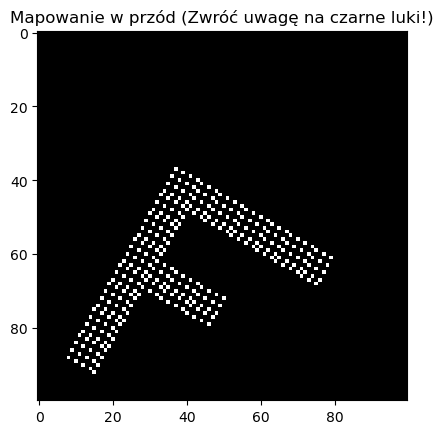

In [33]:
# Zbudowanie złożonej transformacji: powiększenie x2, obrót o 30 stopni i przesunięcie
M = get_translation_matrix(30, 10) @ get_rotation_matrix(30) @ get_scaling_matrix(2.0, 2.0)

out_size = 100
forward_img = np.zeros((out_size, out_size))
height, width = img.shape

for y in range(height):
    for x in range(width):
        # Pomijamy czarne piksele tła dla czytelności (przenosimy tylko literę)
        if img[y, x] == 0: 
            continue
            
        # Wektor jednorodny piksela wejściowego: [x, y, 1]^T
        vec_in = np.array([x, y, 1])
        
        # Mnożenie macierzy przez wektor
        vec_out = M @ vec_in
        
        # Nowe współrzędne (zaokrąglone do najbliższej liczby całkowitej)
        nx = int(np.round(vec_out[0]))
        ny = int(np.round(vec_out[1]))
        
        # Sprawdzenie czy piksel nie wyleciał poza nowy ekran
        if 0 <= nx < out_size and 0 <= ny < out_size:
            forward_img[ny, nx] = img[y, x]

plt.imshow(forward_img, cmap='gray')
plt.title("Mapowanie w przód (Zwróć uwagę na czarne luki!)")
plt.show()

### 3. Mapowanie w tył (Inverse Mapping) - Właściwe rozwiązanie
Aby uniknąć dziur (powstających, gdy zaokrąglone punkty rozchodzą się przy powiększaniu lub obrocie), odwracamy proces. 
Przechodzimy po KAŻDYM pikselu pustego ekranu docelowego i przy użyciu **odwrotności macierzy (Inverse Matrix)** pytamy: *"Z jakiego miejsca na starym zdjęciu powinienem pobrać dla ciebie kolor?"*

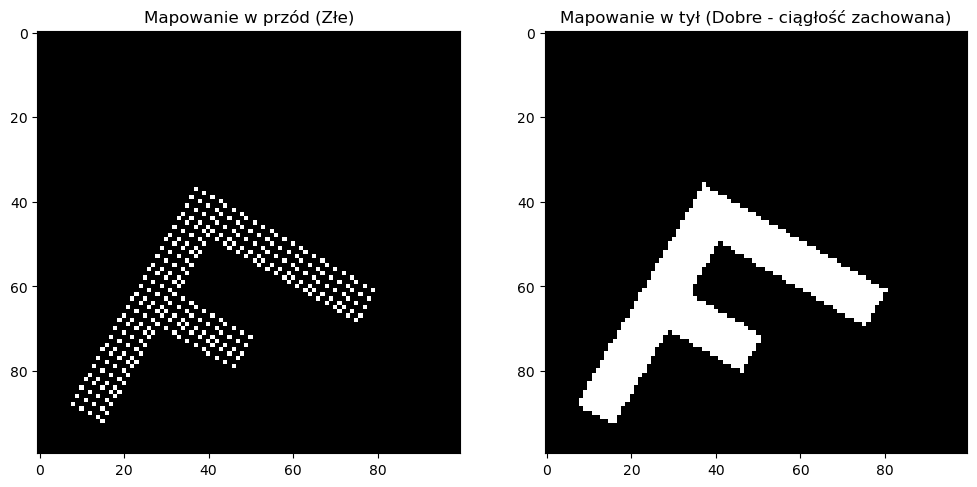

In [24]:
inverse_img = np.zeros((out_size, out_size))

# Odwrócenie macierzy transformacji
M_inv = np.linalg.inv(M)

# Iterujemy po nowym (docelowym) płótnie!
for ny in range(out_size):
    for nx in range(out_size):
        
        vec_out = np.array([nx, ny, 1])
        
        # Szukamy oryginalnych współrzędnych
        vec_in = M_inv @ vec_out
        
        ox = int(np.round(vec_in[0]))
        oy = int(np.round(vec_in[1]))
        
        # Jeśli odnalezione źródło mieści się w oryginalnym obrazku, pobierz kolor
        if 0 <= ox < width and 0 <= oy < height:
            inverse_img[ny, nx] = img[oy, ox]

fig, ax = plt.subplots(1, 2, figsize=(12, 6))
ax[0].imshow(forward_img, cmap='gray')
ax[0].set_title("Mapowanie w przód (Złe)")
ax[1].imshow(inverse_img, cmap='gray')
ax[1].set_title("Mapowanie w tył (Dobre - ciągłość zachowana)")
plt.show()